# Portfolioopdracht 1. Voorspel herseninfarct

In deze opdracht ontwikkelen en vergelijken we verschillende machine-learningmodellen om te voorspellen of een patiënt een verhoogd risico heeft op een herseninfarct. We analyseren en verwerken de data, evalueren modellen met geschikte metrics en verbeteren de prestaties met onder andere cross-validation, hyperparameter tuning en technieken voor imbalanced data. De modellen worden getest via Kaggle en uiteindelijk vergelijken we de resultaten om een onderbouwd modeladvies te geven.

### Groepsinformatie
#### Teamleden: 
Alisha 

Shalini

Baset

#### Teamnaam Kaggle: ABS

#### Gebruikersnamen Kaggle:
Alisha - alisharampersad

Shalini - shalinibekaroe

Baset - basetpaiman

## Opdracht 1. Exploratieve Data Analyse (EDA)

In dit hoofdstuk wordt de trainingsdataset onderzocht. Eerst bekijken we de structuur van de dataset en de betekenis van de verschillende kolommen. Daarna controleren we of de data geschikt is om te gebruiken voor Machine Learning met Scikit-learn.

In [3]:
#dataset inspecteren
import pandas as pd
df = pd.read_csv("train.csv")

df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


### 1.3 Uitleg van de kolommen

| Kolom | Uitleg |
|---|---|
| `id` | Uniek identificatienummer van een patiënt. |
| `age` | Leeftijd van de patiënt. |
| `hypertension` | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. |
| `heart_disease` | Geeft aan of de patiënt een hartaandoening heeft. |
| `avg_glucose_level` | Gemiddeld glucosegehalte van de patiënt. |
| `bmi` | Body Mass Index (BMI) van de patiënt. |
| `gender_Female` | Dummyvariabele die aangeeft of de patiënt vrouw is. |
| `gender_Male` | Dummyvariabele die aangeeft of de patiënt man is. |
| `gender_Other` | Dummyvariabele voor patiënten met een andere geregistreerde gendercategorie. |
| `ever_married_No` | Dummyvariabele die aangeeft dat de patiënt nooit getrouwd is geweest. |
| `ever_married_Yes` | Dummyvariabele die aangeeft dat de patiënt getrouwd is of is geweest. |
| `work_type_Govt_job` | Dummyvariabele die aangeeft dat de patiënt bij de overheid werkt. |
| `work_type_Never_worked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gewerkt. |
| `work_type_Private` | Dummyvariabele die aangeeft dat de patiënt in de private sector werkt. |
| `work_type_Self-employed` | Dummyvariabele die aangeeft dat de patiënt zelfstandig ondernemer is. |
| `work_type_children` | Dummyvariabele die aangeeft dat de patiënt tot de categorie kinderen behoort. |
| `Residence_type_Rural` | Dummyvariabele die aangeeft dat de patiënt in een landelijk gebied woont. |
| `Residence_type_Urban` | Dummyvariabele die aangeeft dat de patiënt in een stedelijk gebied woont. |
| `smoking_status_formerly smoked` | Dummyvariabele die aangeeft dat de patiënt vroeger heeft gerookt. |
| `smoking_status_never smoked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gerookt. |
| `smoking_status_smokes` | Dummyvariabele die aangeeft dat de patiënt momenteel rookt. |
| `stroke` | Doelvariabele. Geeft aan of de patiënt een herseninfarct heeft gehad. |

In [4]:
#check of dataset voldoet aan eisen voor machine learning 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          33550 non-n

### 1.4.1 ML vereisten
De data voldoet aan de eisen om machine learning toe te passen:

1.) De data is numeriek: De categorische variabelen zijn al grotendeels omgezet naar dummyvariabelen. Hierdoor zijn deze variabelen numeriek weergegeven.

2.) De data is in een Pandas Dataframe

3.) De data bevat geen missende waardes -> dit kunnen we zien aan 'non-null' bij alle kolommen

### 1.4.2 Datatypes en basisstatistieken

In [5]:
#datatypes weergeven
display(df.dtypes)

id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

#### Toelichting datatypes
Een float is een getal met een decimaal

Een integer is een geheel getal

Een boolean is een waarde die True of False kan zijn


In [6]:
#basisstatistieken weergeven
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


### 1.4.3 Relaties tussen de onafhankelijke variabelen en stroke

De afhankelijke variabele is `stroke` (0 = geen herseninfarct, 1 = wel) en alle andere kolommen (behalve `id`) zijn de onafhankelijke variabelen en omdat maar ongeveer 1,5% van de patienten stroke heeft, kijken we vooral naar percentages en niet naar aantallen anders is de stroke-groep in de grafieken bijna niet te zien.

we doen dit in vier stappen:
1. correlatie van iedere variabele met stroke (eerste overzicht)
2. boxplots van de numerieke variabelen (`age`, `avg_glucose_level`, `bmi`)
3. percentage stroke per groep voor de ja/nee-kolommen (hypertensie, hartziekte en de dummykolommen)
4. percentage stroke per leeftijdsgroep

#### Stap 1: correlatie met stroke.  - Heatmap maken

De correlatie laat zien hoe sterk een variabele samenhangt met stroke (tussen -1 en 1). Positief betekent: hogere waarde (of kenmerk aanwezig) gaat samen met vaker stroke. De True/False-kolommen zetten we hiervoor om naar 1/0. De kolom `id` laten we weg, want dat is alleen een patientnummer.

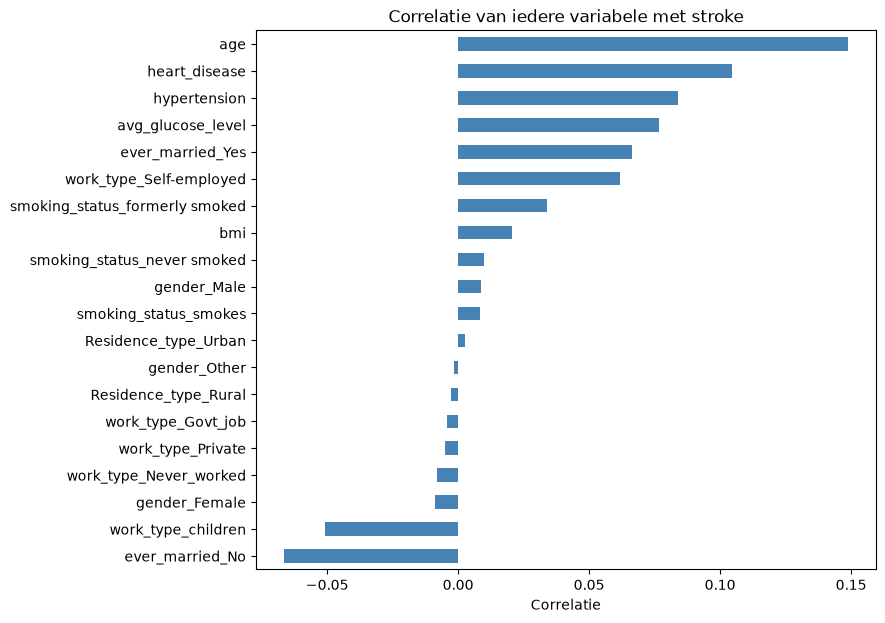

In [7]:
# importeren voor de grafieken
import matplotlib.pyplot as plt
import seaborn as sns

# id weglaten en True/False omzetten naar 1/0 zodat we kunnen rekenen
df_num = df.drop(columns=["id"]).astype(float)

# correlatie van iedere kolom met stroke, van hoog naar laag
correlaties = df_num.corr()["stroke"].drop("stroke").sort_values()

# horizontale staafgrafiek van de correlaties
correlaties.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.title("Correlatie van iedere variabele met stroke")
plt.xlabel("Correlatie")
plt.show()

**Wat zien we?** `age` heeft de sterkste correlatie met stroke (0,149), daarna `heart_disease` (0,105), `hypertension` (0,084) en `avg_glucose_level` (0,077). `bmi` (0,021), gender en woonplaats hebben bijna geen correlatie. Alle correlaties zijn klein en dat komt ook doordat stroke zo weinig voorkomt. Daarom bekijken we de variabelen hieronder ook nog apart.

#### Stap 2: numerieke variabelen (boxplots)

Met een boxplot vergelijken we de verdeling van `age`, `avg_glucose_level` en `bmi` tussen patiënten zonder stroke (0) en met stroke (1). De streep in de doos is de mediaan; de doos bevat de middelste 50% van de patiënten.

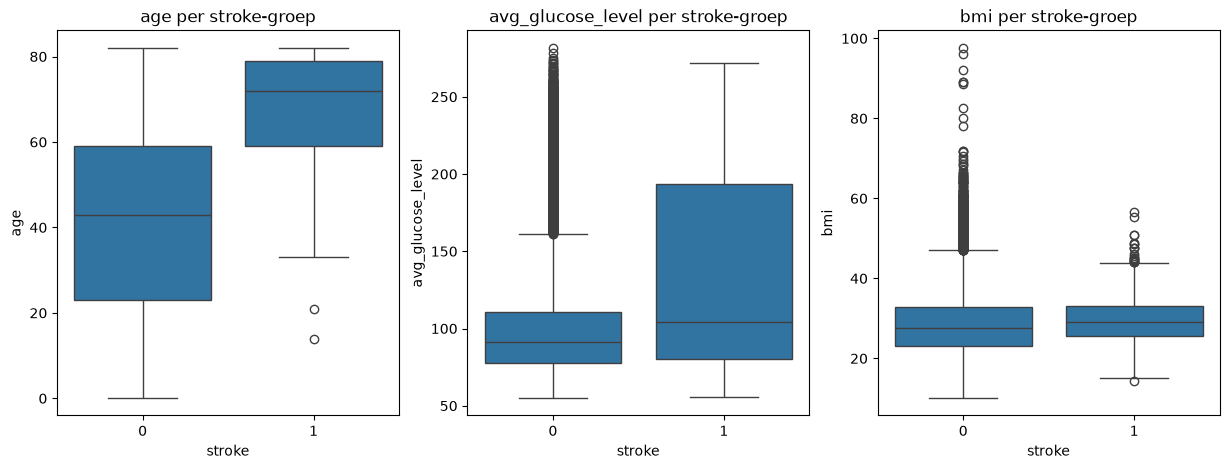

In [8]:
# drie boxplots naast elkaar: per variabele stroke 0 tegenover stroke 1
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kolom in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.boxplot(data=df, x="stroke", y=kolom, ax=ax)
    ax.set_title(f"{kolom} per stroke-groep")
plt.show()

**Wat zien we?**
- **age**: patiënten met stroke zijn duidelijk ouder. De mediane leeftijd is ongeveer 72 jaar bij stroke en 43 jaar zonder stroke.
- **avg_glucose_level**: bij stroke ligt de mediaan hoger (ongeveer 104 tegenover 91) en de doos loopt veel verder omhoog. Een deel van de stroke-patiënten heeft dus een hoog glucosegehalte.
- **bmi**: de boxen lijken erg op elkaar dus BMI hangt weinig samen met stroke. Er zijn wel uitschieters met een extreem hoge BMI (tot 97,6).

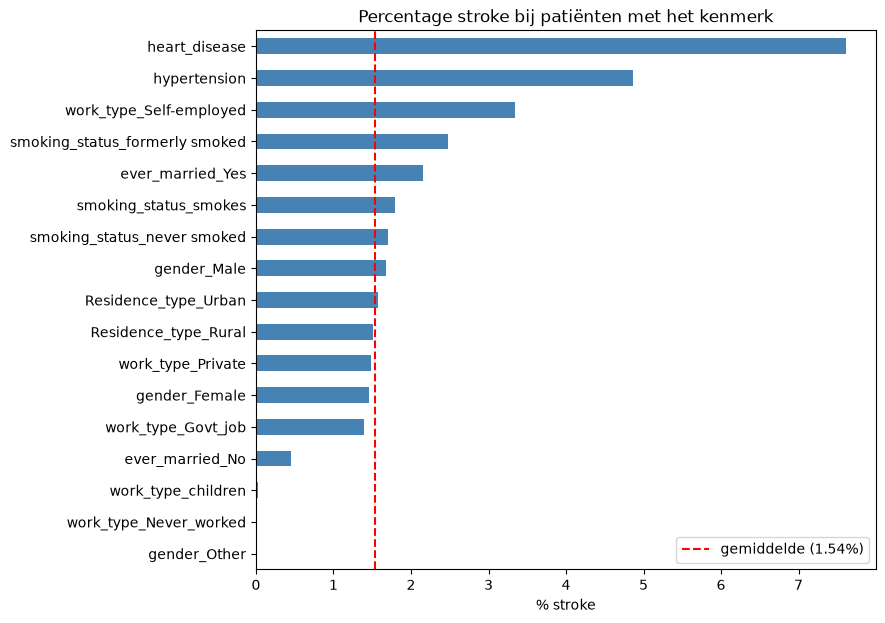

gender_Other                      0.00
work_type_Never_worked            0.00
work_type_children                0.02
ever_married_No                   0.45
work_type_Govt_job                1.40
gender_Female                     1.45
work_type_Private                 1.49
Residence_type_Rural              1.51
Residence_type_Urban              1.57
gender_Male                       1.67
smoking_status_never smoked       1.70
smoking_status_smokes             1.79
ever_married_Yes                  2.16
smoking_status_formerly smoked    2.47
work_type_Self-employed           3.34
hypertension                      4.87
heart_disease                     7.62
dtype: float64

In [9]:
# functie: percentage stroke bij patiënten waarbij de kolom 1 (True) is
def stroke_percentage(kolom):
    groep = df[df[kolom] == 1]
    return groep["stroke"].mean() * 100


# alle ja/nee-kolommen (alles behalve id, de numerieke kolommen en stroke)
ja_nee_kolommen = df.columns.drop(
    ["id", "age", "avg_glucose_level", "bmi", "stroke"])

# percentage per kolom berekenen en sorteren
percentages = pd.Series(
    {kolom: stroke_percentage(kolom) for kolom in ja_nee_kolommen}
).sort_values()

# gemiddelde percentage stroke in de hele dataset
gemiddelde = df["stroke"].mean() * 100

# staafgrafiek met het gemiddelde als stippellijn
percentages.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.axvline(gemiddelde, color="red", linestyle="--",
            label=f"gemiddelde ({gemiddelde:.2f}%)")
plt.title("Percentage stroke bij patiënten met het kenmerk")
plt.xlabel("% stroke")
plt.legend()
plt.show()

percentages.round(2)

**Wat zien we?**
- **heart_disease** (7,62%) en **hypertension** (4,87%) hebben het hoogste percentage stroke: veel hoger dan het gemiddelde van 1,54%.
- **work_type_Self-employed** (3,34%), **smoking_status_formerly smoked** (2,47%) en **ever_married_Yes** (2,16%) liggen ook boven het gemiddelde. Dit zijn vaak oudere mensen, dus dit komt waarschijnlijk voor een groot deel door de leeftijd.
- **work_type_children** (0,02%), **work_type_Never_worked** (0%) en **ever_married_No** (0,45%) liggen ver onder het gemiddelde; dit zijn vooral jonge mensen.
- **Residence_type** (Rural 1,51%, Urban 1,57%) en **gender** (vrouw 1,45%, man 1,67%) maken weinig verschil. `gender_Other` heeft 0% maar bestaat uit maar 6 patiënten, dus daar kunnen we niets over zeggen.

#### Stap 4: percentage stroke per leeftijdsgroep

Omdat leeftijd de sterkste relatie heeft, delen we de patiënten op in leeftijdsgroepen van 10 jaar en berekenen we per groep het percentage stroke.

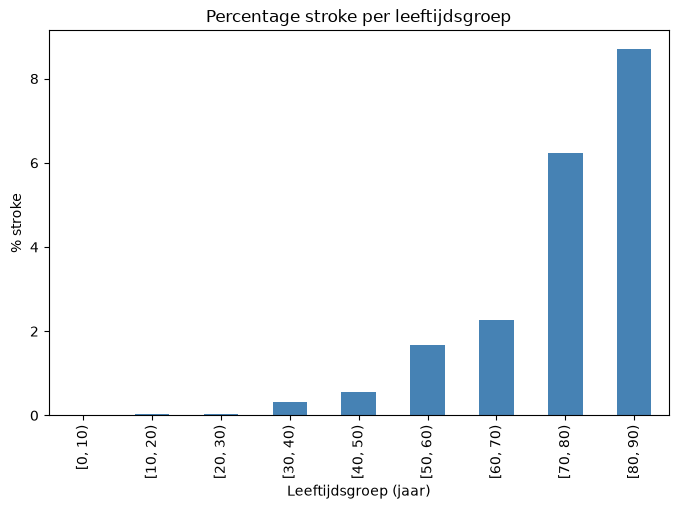

age
[0, 10)     0.00
[10, 20)    0.03
[20, 30)    0.02
[30, 40)    0.33
[40, 50)    0.55
[50, 60)    1.67
[60, 70)    2.28
[70, 80)    6.24
[80, 90)    8.71
Name: stroke, dtype: float64

In [10]:
# leeftijd opdelen in groepen van 10 jaar: [0, 10), [10, 20), ...
leeftijdsgroep = pd.cut(df["age"], bins=range(0, 100, 10), right=False)

# percentage stroke per leeftijdsgroep
per_groep = df.groupby(leeftijdsgroep, observed=True)["stroke"]
stroke_per_leeftijd = per_groep.mean() * 100

# staafgrafiek
stroke_per_leeftijd.plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Percentage stroke per leeftijdsgroep")
plt.xlabel("Leeftijdsgroep (jaar)")
plt.ylabel("% stroke")
plt.show()

stroke_per_leeftijd.round(2)

**Wat zien we?** Onder de 30 jaar komt stroke bijna niet voor (0 tot 0,03%). Vanaf 50 jaar stijgt het percentage duidelijk: 1,67% (50–60), 2,28% (60–70), 6,24% (70–80) en 8,71% (80+). Hoe ouder, hoe groter de kans op stroke.

### 1.4.4 Belangrijkste bevindingen van de EDA

**Onze bevindingen van de EDA:**

1. **De data is sterk ongebalanceerd.** Maar 1,54% van de patienten heeft een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al ongeveer 98,5% accuracy, maar vindt geen enkele stroke-patiënt. Accuracy is dus geen goede maatstaf; we moeten letten op bijvoorbeeld recall en F1-score (de maatstaf van de Kaggle-competitie).
2. **Leeftijd is de belangrijkste variabele.** Stroke komt onder de 30 bijna niet voor en stijgt naar 8,71% bij 80 jaar en ouder.
3. **Hartziekte en hypertensie hangen duidelijk samen met stroke** (7,62% en 4,87% tegenover gemiddeld 1,54%).
4. **Een hoog glucosegehalte hangt samen met stroke.** Stroke-patienten hebben vaker een hoog glucosegehalte.
5. **Sommige verbanden komen waarschijnlijk door leeftijd.** Getrouwde mensen, zelfstandigen en ex-rokers hebben vaker stroke, maar zijn ook gemiddeld ouder kindere en mensen die nooit gewerkt hebben, hebben bijna nooit stroke omdat ze jong zijn.
6. **BMI, geslacht en woonplaats hebben weinig invloed** op stroke.
7. **Geen enkele variabele voorspelt stroke alleen goed.** Zelfs bij 80+ heeft ruim 91% geen stroke. Het model zal daarom meerdere variabelen samen moeten gebruiken en waarschijnlijk ook patienten onterecht als risico aanwijzen. In een medische context is dat minder erg dan een stroke-patient missen.

### 1.4.5 Data opschonen 

In [11]:
def datakwaliteit(df):
    """Geeft een overzicht van mogelijke datakwaliteitsproblemen in de dataset."""
    resultaten = {
        "ontbrekende waarden": df.isna().sum().sum(),
        "dubbele regels (alle kolommen)": df.duplicated().sum(),
        "dubbele patient-id's": df["id"].duplicated().sum(),
        "leeftijd < 0 of > 120": ((df["age"] < 0) | (df["age"] > 120)).sum(),
        "glucose <= 0": (df["avg_glucose_level"] <= 0).sum(),
        "bmi <= 0": (df["bmi"] <= 0).sum(),
    }
    return pd.Series(resultaten)


datakwaliteit(df)

ontbrekende waarden               0
dubbele regels (alle kolommen)    0
dubbele patient-id's              0
leeftijd < 0 of > 120             0
glucose <= 0                      0
bmi <= 0                          0
dtype: int64

**Toelichting:** Er zijn geen ontbrekende waarden, geen dubbele regels en geen dubbele patiënt-id's. Ook zijn er geen onmogelijke waarden voor leeftijd, glucose of BMI. Op basis van deze controles hoeven we dus geen regels te verwijderen wegens datakwaliteitsproblemen.

-other : 6 
-leeftijd 376 rec onder 0,8 

In [12]:
patient_ids = df["id"]
df_model = df.drop(columns=["id"])

# boolean-kolommen (True/False) zijn eigenlijk 0/1-categorieen: omzetten naar int
kolommen_bool = df_model.select_dtypes(include="bool").columns
df_model[kolommen_bool] = df_model[kolommen_bool].astype(int)

print(f"Aantal rijen: {df_model.shape[0]}")
print(f"Aantal kolommen (na verwijderen van id): {df_model.shape[1]}")
print(f"Aantal omgezette boolean-kolommen: {len(kolommen_bool)}")
print(df_model.dtypes.value_counts())

Aantal rijen: 33550
Aantal kolommen (na verwijderen van id): 21
Aantal omgezette boolean-kolommen: 15
int64      18
float64     3
Name: count, dtype: int64


## Bevindingen 

**1. De kolom `id`**

`id` is een uniek administratief nummer per patiënt en heeft geen medische of statistische relatie met stroke (dit hebben we in de correlatie-analyse in 1.4.3 ook niet gebruikt). Voor het trainen van een model voegt deze kolom dus geen voorspellende waarde toe en kan hij een model zelfs in de war brengen als hij per ongeluk als kenmerk wordt meegenomen. We verwijderen `id` daarom uit de data die we gebruiken om te modelleren, maar bewaren de id's apart, omdat we die van `test.csv` nodig hebben voor de Kaggle-inzending.

**2. `gender_Other` (6 patiënten)**

Deze groep bestaat uit 6 patiënten (0,02% van de dataset), van wie niemand stroke heeft gehad. We verwijderen deze rijen niet: het zijn geen foutieve waarden maar een geldige, zij het kleine, categorie. Het verwijderen van echte patiënten zou de toch al kleine stroke-groep (517 van de 33.550, oftewel 1,54%) verder verkleinen. We houden er wel rekening mee dat deze categorie te klein is om harde conclusies over te trekken, en dat we bij cross-validation gestratificeerd moeten splitsen zodat deze groep niet toevallig helemaal in één fold terechtkomt.

**3. Patiënten jonger dan 1 jaar (376 rijen, jongste patiënt 0,08 jaar ≈ 1 maand)**

Dit lijkt ongebruikelijk, maar een leeftijd van enkele maanden is medisch gezien een geldige waarde: stroke bij zeer jonge kinderen (perinatale stroke) komt weliswaar zeldzaam voor, maar bestaat. Dit zijn dus geen foutieve regels en we laten ze staan.

**4. Extreme BMI-waarde (max. 97,6)**

Deze waarde valt ver buiten de rest van de verdeling (75e percentiel ligt op 32,8), maar een BMI van 97,6 is medisch gezien - zij het zeer zeldzaam - mogelijk, en we hebben geen aanwijzing dat het om een fout gaat (bijvoorbeeld een verkeerd ingevoerde eenheid). Omdat we sowieso al weinig stroke-patiënten hebben, verwijderen we liever geen rijen op basis van een vermoeden. Modellen die gevoelig zijn voor uitschieters (zoals KNN of SVM) houden we hier bij standaardisatie (1.6) rekening mee.

### 1.4.6 Standaardiseren



Standaardiseren van data, ook wel z-score normalisatie genoemd, is een voorbewerkingstechniek waarbij elke waarde van een numerieke kolom wordt herschaald volgens de formule

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaarddeviatie van die kolom is (scikit-learn developers, z.d.-a). Na deze transformatie heeft de kolom een gemiddelde van 0 en een standaarddeviatie van 1, waardoor alle gestandaardiseerde kolommen dezelfde schaal krijgen. De onderlinge verhoudingen tussen de waarden, en dus de vorm van de verdeling, blijven daarbij hetzelfde: alleen de schaal verandert, niet de informatie in de data.

Standaardisatie is met name gewenst bij algoritmes die gevoelig zijn voor de schaal van de invoerkenmerken, omdat zij rekenen met afstanden of met gradients (Géron, 2019; scikit-learn developers, z.d.-a). Bij KNN wordt bijvoorbeeld de (euclidische) afstand tussen patiënten berekend om de dichtstbijzijnde buren te bepalen; zonder standaardisatie domineert een kenmerk met een groot bereik, zoals `avg_glucose_level` (55-282), automatisch de afstand ten opzichte van een kenmerk met een kleiner bereik, zoals `age` (0-82), ook wanneer dat laatste kenmerk inhoudelijk net zo belangrijk of belangrijker is (scikit-learn developers, z.d.-b). Logistic Regression wordt getraind met gradient descent, een iteratief optimalisatieproces dat trager en instabieler convergeert wanneer kenmerken sterk verschillende schalen hebben, omdat kenmerken met grote waarden tot grotere gradients leiden (Géron, 2019). Ook SVM is gevoelig voor schaal, omdat dit model de scheidingslijn zoekt met de grootste marge tussen klassen, wat eveneens op afstanden is gebaseerd; een kenmerk met een grote schaal kan daardoor ten onrechte de gevonden scheidingslijn domineren (scikit-learn developers, z.d.-a). Boomgebaseerde modellen zoals Decision Tree, Random Forest, Gradient Boosting en XGBoost zijn daarentegen volledig invariant voor het schalen van kenmerken: zij splitsen per kenmerk op basis van een drempelwaarde, en de volgorde van de waarden - en daarmee de gevonden splitsingen - verandert niet door standaardisatie (Müller & Guido, 2016). Voor deze modellen is standaardisatie dus niet nodig, al is het ook niet schadelijk.

Voor deze dataset voegt standaardisatie waarde toe, specifiek voor de drie continue numerieke kenmerken `age`, `avg_glucose_level` en `bmi`. Zoals te zien was in de basisstatistieken in 1.4.2, hebben deze kenmerken duidelijk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot ruim 280 en `bmi` van 10 tot bijna 98. Zonder standaardisatie zou `avg_glucose_level` dus een onevenredig grote invloed krijgen bij afstandsgebaseerde modellen zoals KNN en SVM, en zou Logistic Regression trager convergeren - wat we ook daadwerkelijk zagen, want ons Logistic Regression-model gaf hierboven zonder standaardisatie een `ConvergenceWarning`. De overige kolommen (`hypertension`, `heart_disease` en alle one-hot encoded kolommen, zoals `gender_Male` of `smoking_status_smokes`) standaardiseren we bewust niet: dit zijn al 0/1-indicatoren met een vergelijkbare en betekenisvolle schaal, en standaardiseren zou ze alleen minder interpreteerbaar maken zonder dat dit enig voordeel oplevert.

We voeren de standaardisatie daarom uit met de `StandardScaler` van Scikit-learn, toegepast op alleen deze drie kolommen, en slaan het resultaat op in een losse kopie (`df_gestandaardiseerd`), zodat de oorspronkelijke, ongestandaardiseerde data (`df_model`) beschikbaar blijft voor de boomgebaseerde modellen. Hieronder passen we de standaardisatie toe op de volledige dataset, enkel om het effect te illustreren; bij het daadwerkelijke trainen van modellen in Opdracht 3 herhalen we dit per cross-validation-fold (bijvoorbeeld met een Scikit-learn `Pipeline`), zodat de scaler alleen wordt gefit op trainingsdata en we geen data leakage veroorzaken naar de validatie- of testdata.